# Déchets Plastiques mal gérés et mortalité Infantile (2019)

**Groupe :** GOMA Rayan, PRIBETICH Marius, LUCIBELLO Anton

> En 2019, parmi les pays et territoires disposant des données, observe-t-on une association descriptive entre les déchets plastiques mal gérés par habitant et le taux de mortalité infantile ? Cette association paraît-elle similaire lorsqu’on compare séparément les groupes de PIB par habitant et d’accès à l’assainissement de base ?

Cette analyse compare des indicateurs nationaux. Elle ne démontre pas que le plastique cause des décès et ne décrit pas l’exposition d’un enfant individuellement.

## 1. Sources, variables et méthode

- **Déchets plastiques mal gérés :** Our World in Data, source Meijer et al. (2021), en kg par personne et par an. L’indicateur ne mesure pas directement l’exposition des personnes.
- **Mortalité infantile :** World Bank WDI `SP.DYN.IMRT.IN`, décès avant un an pour 1 000 naissances vivantes.
- **PIB par habitant :** World Bank WDI `NY.GDP.PCAP.PP.KD`, dollars internationaux constants de 2021 en PPA.
- **Assainissement :** World Bank WDI `SH.STA.BASS.ZS`, part de la population ayant accès à au moins un service d’assainissement de base. Ce n’est pas une mesure de la collecte des déchets plastiques.

On filtre les agrégats, on garde l’année 2019, puis on joint les tables par code géographique ISO3 et année. Les données manquantes ne sont pas remplacées par zéro. Le PIB et l’assainissement sont comparés séparément comme contexte; ils ne sont pas présentés comme des contrôles causaux.

## 2. Chargement des bibliothèques et fonctions du projet

`Path` construit des chemins compatibles avec Windows, macOS et Linux. Si le notebook est exécuté seul, il télécharge automatiquement le dépôt du projet pour récupérer le module `prepare_data.py` et la structure des dossiers. `pandas` sert à lire et résumer les tableaux ; `matplotlib` sert à tracer les graphiques.

In [26]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display


PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "cleaning.py").exists():
    if (PROJECT_DIR.parent / "cleaning.py").exists():
        PROJECT_DIR = PROJECT_DIR.parent
    else:
        repo_dir = PROJECT_DIR / "Python-pour-la-data-science"
        if not repo_dir.exists():
            subprocess.run(
                ["git", "clone", "https://github.com/Rayanisworking/Python-pour-la-data-science.git"],
                check=True,
            )
        PROJECT_DIR = repo_dir

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from download import download, RAW_ROOT
from cleaning import prepare_project_data


FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dossier du projet prêt : {PROJECT_DIR}")

Dossier du projet prêt : /home/onyxia/work/Python-pour-la-data-science


## 3. Préparer les tables et vérifier la jointure

Les cellules ci-dessous vérifient d'abord la présence des données brutes dans `data/raw/` (et lancent automatiquement le téléchargement officiel via `download()` si elles sont absentes). La fonction `prepare_project_data()` filtre ensuite les agrégats régionaux, conserve l'année 2019, joint les indicateurs par code pays ISO3 et sauvegarde les tables nettoyées dans `data/cleaned/`.

In [27]:

required_raw_files = [
    RAW_ROOT / "owid_mismanaged_plastic_per_capita.csv",
    RAW_ROOT / "wdi_countries.json",
    RAW_ROOT / "wdi_infant_mortality_2019.json",
    RAW_ROOT / "wdi_gdp_per_capita_ppp_2019.json",
    RAW_ROOT / "wdi_basic_sanitation_2019.json",
]

if not all(f.exists() for f in required_raw_files):
    print("Données brutes manquantes : téléchargement automatique en cours...")
    download()


tables = prepare_project_data()

df_merged = tables["merged"]
df_pair = tables["pair_plastic_infant"]
df_complete = tables["complete"]
df_excluded = tables["excluded"]
country_metadata = tables["country_metadata"]

print(f"Pays/territoires appariés (OWID 2019) : {len(df_merged)}")
print(f"Pays/territoires avec déchets et mortalité : {len(df_pair)}")
print(f"Pays/territoires complets pour les quatre variables : {len(df_complete)}")

Pays/territoires appariés (OWID 2019) : 153
Pays/territoires avec déchets et mortalité : 151
Pays/territoires complets pour les quatre variables : 139


### Bilan de la jointure

Un effectif différent selon les colonnes signifie que certaines sources n'ont pas de valeur renseignée pour certains pays ou territoires. On affiche ci-dessous les effectifs réels à chaque étape du filtrage plutôt que de supprimer silencieusement les données manquantes. Les cas complets servent aux comparaisons par PIB et assainissement; l’association principale utilise tous les cas disponibles pour les deux variables concernées.

In [28]:

audit_df = pd.DataFrame([
    {"controle": "Entités OWID 2019 retenues (pays/territoires)", "effectif": len(df_merged)},
    {"controle": "Entités OWID 2019 exclues (agrégats/hors périmètre)", "effectif": len(df_excluded)},
    {"controle": "Pays avec déchets + mortalité", "effectif": len(df_pair)},
    {"controle": "Cas complets (4 variables)", "effectif": len(df_complete)},
])
display(audit_df)


cols = ["plastic_kg_per_person", "infant_mortality_per_1000", "gdp_pc_ppp_2019", "basic_sanitation_pct"]
missing_df = pd.DataFrame({
    "variable": cols,
    "valeurs_presentes": [df_merged[c].notna().sum() for c in cols],
    "valeurs_manquantes": [df_merged[c].isna().sum() for c in cols],
})
display(missing_df)


range_df = pd.DataFrame({
    "variable": cols,
    "min": [df_merged[c].min() for c in cols],
    "max": [df_merged[c].max() for c in cols],
})
display(range_df)

print("Exemples d'entités OWID exclues du périmètre World Bank :")
display(tables["excluded"].head(10))

,controle,effectif
0,Entités OWID 2019 retenues (pays/territoires),153
1,Entités OWID 2019 exclues (agrégats/hors périm...,12
2,Pays avec déchets + mortalité,151
3,Cas complets (4 variables),139


,variable,valeurs_presentes,valeurs_manquantes
0,plastic_kg_per_person,153,0
1,infant_mortality_per_1000,151,2
2,gdp_pc_ppp_2019,148,5
3,basic_sanitation_pct,145,8


,variable,min,max
0,plastic_kg_per_person,0.002720,69.515860
1,infant_mortality_per_1000,1.800000,75.000000
2,gdp_pc_ppp_2019,1394.764615,120678.341979
3,basic_sanitation_pct,13.169338,100.000000


Exemples d'entités OWID exclues du périmètre World Bank :


,entity,iso3,year,plastic_kg_per_person
0,Africa,OWID_AFR,2019,10.465928
6,Asia,OWID_ASI,2019,8.667235
45,Europe,OWID_EUR,2019,1.580226
49,French Guiana,GUF,2019,0.432990
57,Guadeloupe,GLP,2019,0.405000
91,Martinique,MTQ,2019,0.369681
105,North America,OWID_NAM,2019,5.257716
108,Oceania,OWID_OCE,2019,3.240268
121,Reunion,REU,2019,0.262092
146,Taiwan,TWN,2019,0.315555


## 4. Description des quatre variables

La médiane et les quartiles décrivent le centre et la dispersion sans être autant tirés par les valeurs extrêmes que la moyenne. `n` indique combien de valeurs sont effectivement disponibles pour chaque variable.

In [29]:
variable_info = {
    "plastic_kg_per_person": "Déchets plastiques mal gérés (kg/personne/an)",
    "infant_mortality_per_1000": "Mortalité infantile (décès pour 1 000 naissances)",
    "gdp_pc_ppp_2019": "PIB/habitant (dollars internationaux PPA 2021)",
    "basic_sanitation_pct": "Assainissement de base (% de la population)",
}

summary_rows = []
for column, label in variable_info.items():
    values = df_merged[column].dropna()
    summary_rows.append({
        "variable": label,
        "n": len(values),
        "manquants": int(df_merged[column].isna().sum()),
        "mediane": values.median(),
        "Q1": values.quantile(0.25),
        "Q3": values.quantile(0.75),
        "minimum": values.min(),
        "maximum": values.max(),
    })

df_descriptives = pd.DataFrame(summary_rows)
display(df_descriptives.round(2))
df_descriptives.to_csv(TABLES_DIR / "statistiques_descriptives.csv", index=False)

,variable,n,manquants,mediane,Q1,Q3,minimum,maximum
0,Déchets plastiques mal gérés (kg/personne/an),153,0,6.26,0.54,14.30,0.00,69.52
1,Mortalité infantile (décès pour 1 000 naissances),151,2,13.20,5.55,30.35,1.80,75.00
2,PIB/habitant (dollars internationaux PPA 2021),148,5,17478.10,6708.19,37534.90,1394.76,120678.34
3,Assainissement de base (% de la population),145,8,91.50,66.04,98.65,13.17,100.00


## 5. Graphique 1 — Distributions

Ces histogrammes montrent comment les pays/territoires se répartissent. La ligne verticale indique la médiane de chaque variable. Une longue queue ou quelques valeurs éloignées signalent une distribution asymétrique et invitent à commenter les extrêmes.sente le nuage de points en **échelle linéaire** puis en **échelle logarithmique** afin de mieux visualiser l'ensemble des pays malgré les forts écarts d'échelle.

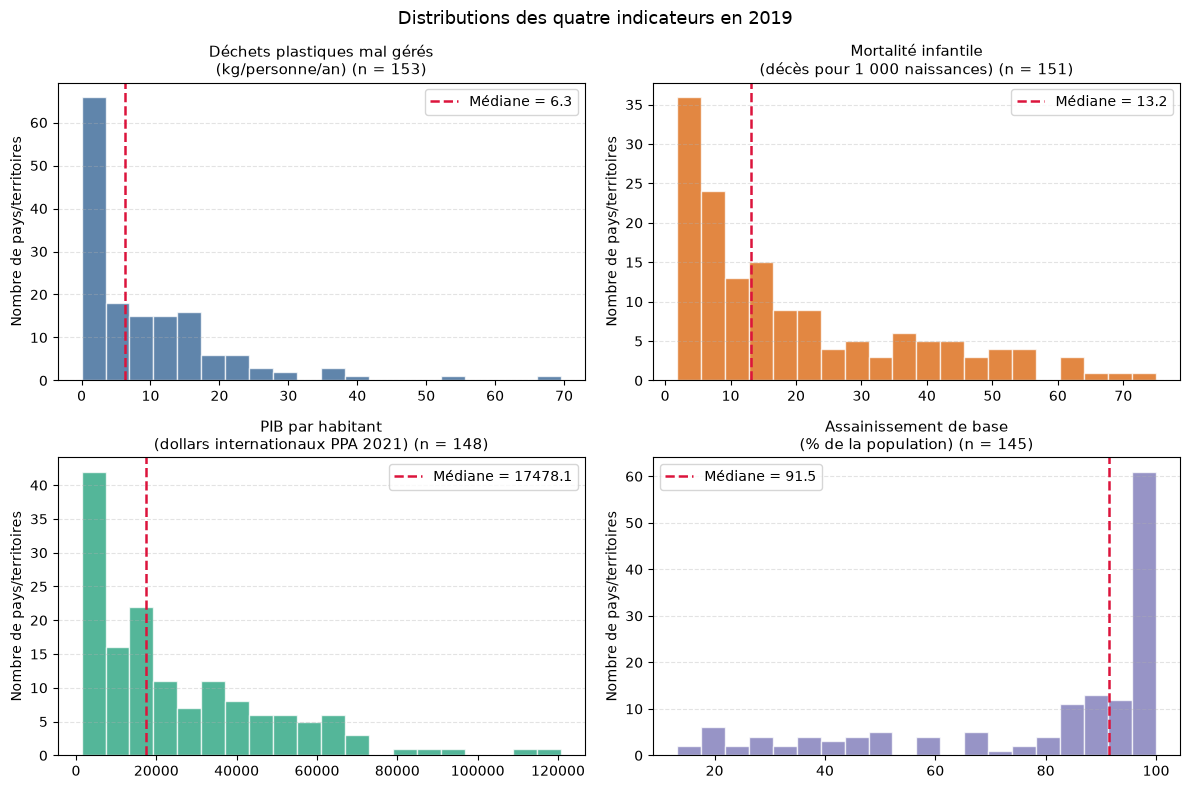

In [30]:
variables_hist = [
    ("plastic_kg_per_person", "Déchets plastiques mal gérés\n(kg/personne/an)", "#2b5c8f"),
    ("infant_mortality_per_1000", "Mortalité infantile\n(décès pour 1 000 naissances)", "#d95f02"),
    ("gdp_pc_ppp_2019", "PIB par habitant\n(dollars internationaux PPA 2021)", "#1b9e77"),
    ("basic_sanitation_pct", "Assainissement de base\n(% de la population)", "#7570b3"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, (col, titre, couleur) in zip(axes, variables_hist):
    valeurs = df_merged[col].dropna()
    med = valeurs.median()

    ax.hist(valeurs, bins=20, color=couleur, alpha=0.75, edgecolor="white")
    ax.axvline(med, color="crimson", linestyle="--", linewidth=1.8, label=f"Médiane = {med:.1f}")
    ax.set_title(f"{titre} (n = {len(valeurs)})", fontsize=10.5)
    ax.set_ylabel("Nombre de pays/territoires")
    ax.legend()
    ax.grid(True, axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Distributions des quatre indicateurs en 2019", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_distributions_2019.png", dpi=150)
plt.show()

## 6. Graphique 2 — Déchets plastiques et mortalité infantile

Ce graphique représente l'association descriptive entre les déchets plastiques mal gérés par habitant et le taux de mortalité infantile en 2019 sur l'ensemble des pays et territoires disposant des deux mesures (`df_pair`).

Pour quantifier cette relation statistique sans présumer d'un lien de causalité, on utilise deux coefficients complémentaires compris entre $-1$ et $+1$ :

- **Le coefficient de corrélation linéaire de Pearson ($r$) :** il mesure l'intensité et le sens d'une relation **linéaire** (proportionnelle) directement entre les valeurs numériques brutes des deux variables. Parce qu'il s'appuie sur les moyennes et les écarts-types, il est très sensible aux valeurs extrêmes et aux distributions asymétriques.
- **Le coefficient de corrélation de rangs de Spearman ($\rho$) :** il remplace d'abord chaque pays par son **rang** (du plus faible au plus élevé pour chaque indicateur), puis mesure la tendance monotone entre ces classements. Il permet de vérifier si, de manière générale, un pays ayant davantage de déchets mal gérés par habitant tend aussi à présenter une mortalité infantile plus élevée, sans que quelques pays extrêmes ne faussent le résultat.

En complément de ces deux indicateurs, le nuage de points est affiché en **échelle linéaire** (à gauche) et en **échelle logarithmique** (à droite) afin de mieux lire l'ensemble de la distribution malgré les forts écarts d'échelle.

Effectif étudié : n = 151 pays/territoires
Corrélation de Pearson (r)     : 0.337
Corrélation de Spearman (rho)  : 0.585


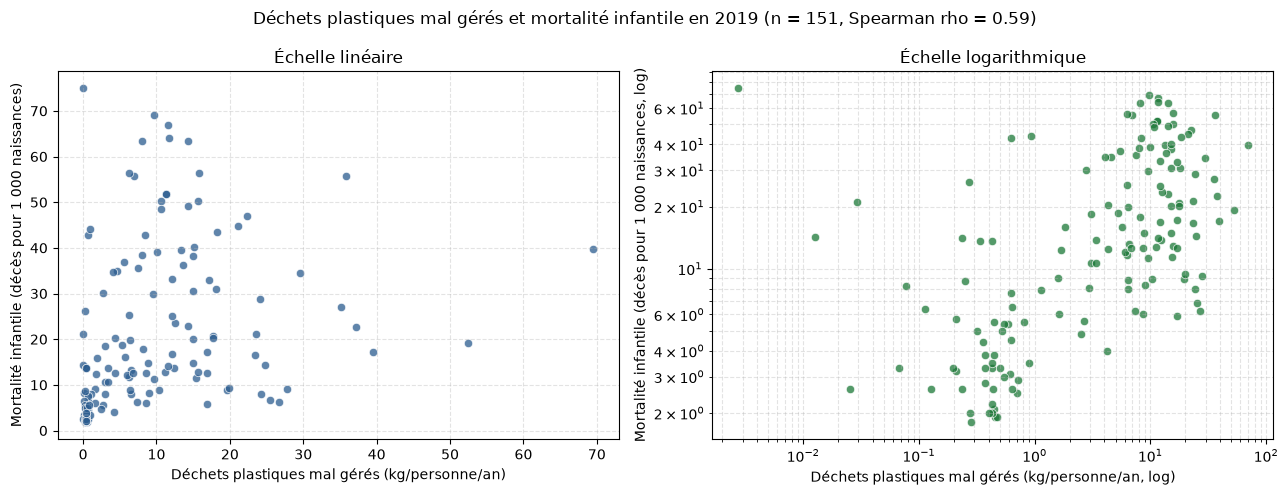

In [31]:
# Calcul des corrélations sur l'échantillon principal (déchets + mortalité)
pearson_r = df_pair["plastic_kg_per_person"].corr(
    df_pair["infant_mortality_per_1000"], method="pearson"
)
spearman_rho = df_pair["plastic_kg_per_person"].corr(
    df_pair["infant_mortality_per_1000"], method="spearman"
)

print(f"Effectif étudié : n = {len(df_pair)} pays/territoires")
print(f"Corrélation de Pearson (r)     : {pearson_r:.3f}")
print(f"Corrélation de Spearman (rho)  : {spearman_rho:.3f}")

# Graphique 2 : nuage de points (échelle linéaire et échelle logarithmique)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panneau gauche : échelle linéaire
axes[0].scatter(
    df_pair["plastic_kg_per_person"],
    df_pair["infant_mortality_per_1000"],
    alpha=0.75,
    color="#2b5c8f",
    edgecolors="white",
    linewidth=0.6,
)
axes[0].set_title("Échelle linéaire")
axes[0].set_xlabel("Déchets plastiques mal gérés (kg/personne/an)")
axes[0].set_ylabel("Mortalité infantile (décès pour 1 000 naissances)")
axes[0].grid(True, linestyle="--", alpha=0.35)

# Panneau droit : échelle logarithmique (valeurs strictement positives)
df_pair_pos = df_pair[
    (df_pair["plastic_kg_per_person"] > 0) & (df_pair["infant_mortality_per_1000"] > 0)
]
axes[1].scatter(
    df_pair_pos["plastic_kg_per_person"],
    df_pair_pos["infant_mortality_per_1000"],
    alpha=0.75,
    color="#1b7837",
    edgecolors="white",
    linewidth=0.6,
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Échelle logarithmique")
axes[1].set_xlabel("Déchets plastiques mal gérés (kg/personne/an, log)")
axes[1].set_ylabel("Mortalité infantile (décès pour 1 000 naissances, log)")
axes[1].grid(True, which="both", linestyle="--", alpha=0.35)

fig.suptitle(
    f"Déchets plastiques mal gérés et mortalité infantile en 2019 (n = {len(df_pair)}, Spearman rho = {spearman_rho:.2f})",
    fontsize=12,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2_dechets_mortalite_2019.png", dpi=150)
plt.show()

## 7. Préparer des groupes sans séparer artificiellement les ex æquo

On utilise les rangs moyens : deux observations qui ont exactement la même valeur reçoivent le même rang et restent dans le même groupe. Les effectifs des groupes peuvent donc différer légèrement. Cette règle est particulièrement utile pour l’assainissement, qui peut avoir de nombreuses valeurs répétées.

In [32]:
def creer_groupes_rangs_moyens(serie, labels):
    """Découpe une série en groupes équilibrés via les rangs moyens sans séparer les ex æquo."""
    rangs_moyens = serie.rank(method="average")
    return pd.qcut(rangs_moyens, q=len(labels), labels=labels)

df_groups = df_complete.copy()

labels_pib = ["PIB faible", "PIB intermédiaire", "PIB élevé"]
labels_assainissement = ["Assainissement faible", "Assainissement intermédiaire", "Assainissement élevé"]

df_groups["groupe_pib"] = creer_groupes_rangs_moyens(df_groups["gdp_pc_ppp_2019"], labels_pib)
df_groups["groupe_assainissement"] = creer_groupes_rangs_moyens(
    df_groups["basic_sanitation_pct"], labels_assainissement
)

# Vérification des effectifs et des bornes de chaque groupe
resume_groupes = []
for dimension, col_grp, col_val in [
    ("PIB par habitant (PPA 2021)", "groupe_pib", "gdp_pc_ppp_2019"),
    ("Assainissement de base (%)", "groupe_assainissement", "basic_sanitation_pct"),
]:
    for grp, sub in df_groups.groupby(col_grp, observed=False):
        resume_groupes.append({
            "Dimension": dimension,
            "Groupe": grp,
            "Effectif (n)": len(sub),
            "Minimum": round(sub[col_val].min(), 2),
            "Maximum": round(sub[col_val].max(), 2),
        })

df_resume_groupes = pd.DataFrame(resume_groupes)
display(df_resume_groupes)

,Dimension,Groupe,Effectif (n),Minimum,Maximum
0,PIB par habitant (PPA 2021),PIB faible,47,1394.76,9712.98
1,PIB par habitant (PPA 2021),PIB intermédiaire,46,10168.36,31300.51
2,PIB par habitant (PPA 2021),PIB élevé,46,33163.72,120678.34
3,Assainissement de base (%),Assainissement faible,47,13.17,81.38
4,Assainissement de base (%),Assainissement intermédiaire,46,83.11,97.53
5,Assainissement de base (%),Assainissement élevé,46,97.58,100.00


## 8. Graphique 3 — mortalité selon les quartiles de déchets

La figure montre la médiane de mortalité dans chaque quartile de déchets, avec l’intervalle interquartile. Elle décrit les différences entre groupes; elle ne prouve pas que l’indicateur de déchets explique à lui seul la différence. Les groupes utilisent les cas complets des quatre variables pour rester cohérents avec les comparaisons suivantes.

,Quartile de déchets plastiques,n,Plastique min - max (kg/hab/an),Médiane mortalité (/1 000),Q1 mortalité,Q3 mortalité
0,Q1 (plus faibles),35,0.0 - 0.5,3.3,2.60,6.05
1,Q2,35,0.5 - 6.0,8.1,5.10,17.25
2,Q3,34,6.2 - 13.3,24.3,12.75,47.15
3,Q4 (plus élevés),35,13.6 - 69.5,22.6,14.65,40.00


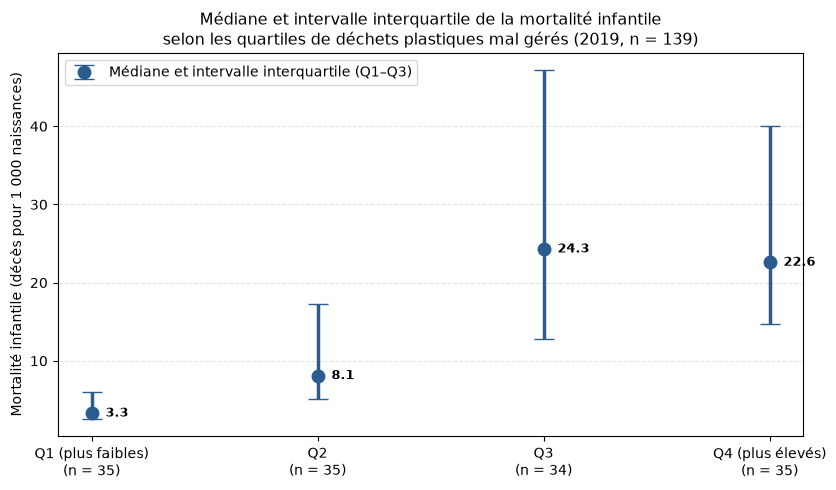

In [33]:
# Découpage des déchets plastiques en 4 quartiles (via les rangs moyens, sur df_complete)
labels_quartiles = [
    "Q1 (plus faibles)",
    "Q2",
    "Q3",
    "Q4 (plus élevés)",
]
df_groups["quartile_dechets"] = creer_groupes_rangs_moyens(
    df_groups["plastic_kg_per_person"], labels_quartiles
)

# Calcul de la médiane et de l'intervalle interquartile (Q1 - Q3) de mortalité par quartile
stats_quartiles = []
for q_label, sub in df_groups.groupby("quartile_dechets", observed=False):
    valeurs_mort = sub["infant_mortality_per_1000"]
    stats_quartiles.append({
        "Quartile de déchets plastiques": q_label,
        "n": len(sub),
        "Plastique min - max (kg/hab/an)": f"{sub['plastic_kg_per_person'].min():.1f} - {sub['plastic_kg_per_person'].max():.1f}",
        "Médiane mortalité (/1 000)": round(valeurs_mort.median(), 2),
        "Q1 mortalité": round(valeurs_mort.quantile(0.25), 2),
        "Q3 mortalité": round(valeurs_mort.quantile(0.75), 2),
    })

df_quartiles_summary = pd.DataFrame(stats_quartiles)
display(df_quartiles_summary)
df_quartiles_summary.to_csv(TABLES_DIR / "mortalite_par_quartile_dechets_2019.csv", index=False)

# Graphique 3 : médiane et intervalle interquartile (barres d'erreur Q1 - Q3)
fig, ax = plt.subplots(figsize=(8.5, 5))

x_pos = range(len(df_quartiles_summary))
medianes = df_quartiles_summary["Médiane mortalité (/1 000)"]
err_inf = medianes - df_quartiles_summary["Q1 mortalité"]
err_sup = df_quartiles_summary["Q3 mortalité"] - medianes

ax.errorbar(
    x_pos,
    medianes,
    yerr=[err_inf, err_sup],
    fmt="o",
    color="#2b5c8f",
    ecolor="#2b5c8f",
    elinewidth=2.5,
    capsize=7,
    markersize=9,
    label="Médiane et intervalle interquartile (Q1–Q3)",
)

# Affichage de la valeur de la médiane à côté de chaque point
for i, med in enumerate(medianes):
    ax.annotate(
        f"{med:.1f}",
        (i, med),
        textcoords="offset points",
        xytext=(10, 0),
        va="center",
        fontsize=9.5,
        fontweight="bold",
    )

ax.set_xticks(list(x_pos))
ax.set_xticklabels(
    [f"{row['Quartile de déchets plastiques']}\n(n = {row['n']})" for _, row in df_quartiles_summary.iterrows()]
)
ax.set_ylabel("Mortalité infantile (décès pour 1 000 naissances)")
ax.set_title(
    f"Médiane et intervalle interquartile de la mortalité infantile\nselon les quartiles de déchets plastiques mal gérés (2019, n = {len(df_groups)})",
    fontsize=11.5,
)
ax.grid(True, axis="y", linestyle="--", alpha=0.35)
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig3_mortalite_quartiles_dechets_2019.png", dpi=150)
plt.show()

## 9. Comparer séparément selon le PIB et l’assainissement

On calcule la corrélation de Spearman dans chaque groupe de PIB, puis dans chaque groupe d’assainissement. Le calcul reste descriptif. Les effectifs sont indiqués; une corrélation de groupe est instable lorsque le groupe est petit ou que l’une des variables varie peu. Les tertiles sont définis sur l’échantillon complet de quatre variables, et non sur des groupes croisés PIB × assainissement.

In [34]:
comparaison_rows = []

dimensions = [
    ("PIB par habitant (PPA 2021)", "groupe_pib", "gdp_pc_ppp_2019"),
    ("Assainissement de base (%)", "groupe_assainissement", "basic_sanitation_pct"),
]

for dimension_label, col_groupe, col_var in dimensions:
    for groupe, sub in df_groups.groupby(col_groupe, observed=False):
        spearman_grp = sub["plastic_kg_per_person"].corr(
            sub["infant_mortality_per_1000"], method="spearman"
        )
        comparaison_rows.append({
            "Dimension": dimension_label,
            "Groupe (tercile)": groupe,
            "n": len(sub),
            "Plage du critère": f"{sub[col_var].min():.1f} – {sub[col_var].max():.1f}",
            "Médiane plastique (kg/hab/an)": round(sub["plastic_kg_per_person"].median(), 2),
            "Médiane mortalité (/1 000)": round(sub["infant_mortality_per_1000"].median(), 2),
            "Spearman (rho)": round(spearman_grp, 3),
        })

df_comparaison_groupes = pd.DataFrame(comparaison_rows)
display(df_comparaison_groupes)
df_comparaison_groupes.to_csv(TABLES_DIR / "comparaison_pib_assainissement_2019.csv", index=False)

,Dimension,Groupe (tercile),n,Plage du critère,Médiane plastique (kg/hab/an),Médiane mortalité (/1 000),Spearman (rho)
0,PIB par habitant (PPA 2021),PIB faible,47,1394.8 – 9713.0,10.65,38.40,0.210
1,PIB par habitant (PPA 2021),PIB intermédiaire,46,10168.4 – 31300.5,8.76,12.55,0.269
2,PIB par habitant (PPA 2021),PIB élevé,46,33163.7 – 120678.3,0.46,3.50,0.390
3,Assainissement de base (%),Assainissement faible,47,13.2 – 81.4,11.30,39.60,0.151
4,Assainissement de base (%),Assainissement intermédiaire,46,83.1 – 97.5,6.85,12.20,0.572
5,Assainissement de base (%),Assainissement élevé,46,97.6 – 100.0,0.50,4.10,0.494


### Graphique 4 — association de rang dans chaque groupe

Le point représente le coefficient de Spearman, pas une pente causale. La ligne verticale indique zéro. Les effectifs sont écrits à côté des points. L’échelle commune de −1 à 1 permet de lire le sens et la dispersion des coefficients des deux découpages.

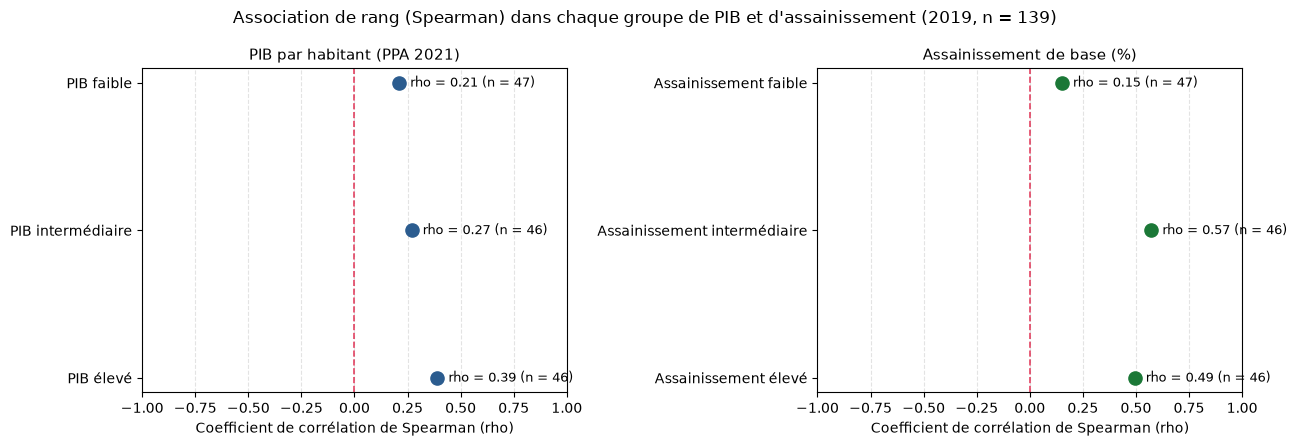

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)

decoupages = [
    ("PIB par habitant (PPA 2021)", "#2b5c8f"),
    ("Assainissement de base (%)", "#1b7837"),
]

for ax, (dimension, couleur) in zip(axes, decoupages):
    sub = df_comparaison_groupes[
        df_comparaison_groupes["Dimension"] == dimension
    ].reset_index(drop=True)

    y_pos = list(range(len(sub)))
    rhos = sub["Spearman (rho)"]
    effectifs = sub["n"]

    ax.axvline(0, color="crimson", linestyle="--", linewidth=1.2, alpha=0.8)
    ax.scatter(rhos, y_pos, color=couleur, s=90, zorder=3)

    # Écriture de la valeur de rho et de l'effectif n à côté de chaque point
    for y, rho, n in zip(y_pos, rhos, effectifs):
        decalage = 8 if rho <= 0.75 else -8
        alignement = "left" if rho <= 0.75 else "right"
        ax.annotate(
            f"rho = {rho:.2f} (n = {n})",
            (rho, y),
            textcoords="offset points",
            xytext=(decalage, 0),
            va="center",
            ha=alignement,
            fontsize=9.5,
        )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(sub["Groupe (tercile)"])
    ax.invert_yaxis()  # Affiche le groupe faible en haut et élevé en bas
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Coefficient de corrélation de Spearman (rho)")
    ax.set_title(dimension, fontsize=11)
    ax.grid(True, axis="x", linestyle="--", alpha=0.35)

fig.suptitle(
    f"Association de rang (Spearman) dans chaque groupe de PIB et d'assainissement (2019, n = {len(df_groups)})",
    fontsize=12,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig4_spearman_par_groupe_2019.png", dpi=150)
plt.show()

## 10. Sensibilité au choix de l’échantillon

La question principale nécessite seulement déchets et mortalité; les comparaisons par groupes nécessitent les quatre indicateurs. On compare donc les deux coefficients pour voir si le retrait des entités sans PIB ou assainissement change la lecture. Cette comparaison ne remplace pas l’analyse des raisons pour lesquelles des valeurs manquent.

In [36]:
# 1. Comparaison des coefficients entre l'échantillon principal (df_pair) et les cas complets (df_complete)
sensibilite_rows = []
for nom_echantillon, df_sub in [
    ("Échantillon principal (déchets + mortalité)", df_pair),
    ("Cas complets (les 4 indicateurs renseignés)", df_complete),
]:
    r_pearson = df_sub["plastic_kg_per_person"].corr(
        df_sub["infant_mortality_per_1000"], method="pearson"
    )
    rho_spearman = df_sub["plastic_kg_per_person"].corr(
        df_sub["infant_mortality_per_1000"], method="spearman"
    )
    sensibilite_rows.append({
        "Échantillon": nom_echantillon,
        "Effectif (n)": len(df_sub),
        "Médiane plastique (kg/hab/an)": round(df_sub["plastic_kg_per_person"].median(), 2),
        "Médiane mortalité (/1 000)": round(df_sub["infant_mortality_per_1000"].median(), 2),
        "Pearson (r)": round(r_pearson, 3),
        "Spearman (rho)": round(rho_spearman, 3),
    })

df_sensibilite = pd.DataFrame(sensibilite_rows)
display(df_sensibilite)
df_sensibilite.to_csv(TABLES_DIR / "sensibilite_echantillon_2019.csv", index=False)

# 2. Liste des pays/territoires présents dans df_pair mais absents de df_complete
codes_complets = set(df_complete["iso3"])
df_retires = df_pair.loc[
    ~df_pair["iso3"].isin(codes_complets),
    ["entity", "iso3", "plastic_kg_per_person", "infant_mortality_per_1000", "gdp_pc_ppp_2019", "basic_sanitation_pct"],
].copy()

print(f"Entités retirées lors du passage aux cas complets : {len(df_retires)}")
if not df_retires.empty:
    display(df_retires)

,Échantillon,Effectif (n),Médiane plastique (kg/hab/an),Médiane mortalité (/1 000),Pearson (r),Spearman (rho)
0,Échantillon principal (déchets + mortalité),151,6.27,13.2,0.337,0.585
1,Cas complets (les 4 indicateurs renseignés),139,5.98,12.9,0.348,0.608


Entités retirées lors du passage aux cas complets : 12


,entity,iso3,plastic_kg_per_person,infant_mortality_per_1000,gdp_pc_ppp_2019,basic_sanitation_pct
4,Argentina,ARG,10.401912,8.9,26629.552942,NaN
13,Bosnia and Herzegovina,BIH,16.828537,5.9,17029.297198,NaN
34,Dominica,DMA,15.027778,30.6,17619.433542,NaN
40,Equatorial Guinea,GNQ,6.934366,55.7,18446.591658,NaN
41,Eritrea,ERI,24.045753,28.7,NaN,NaN
89,Monaco,MCO,0.128205,2.6,NaN,100.000000
97,Nicaragua,NIC,16.935839,12.6,6756.593340,NaN
99,North Korea,PRK,0.012546,14.3,NaN,84.619492
115,Saint Kitts and Nevis,KNA,1.830189,15.9,31512.194311,NaN
117,Saint Vincent and the Grenadines,VCT,11.126126,12.8,16365.325579,NaN
